# Task 3: Customer Cohort & Churn Analytics

**Program:** Datheon Data Analytics & Power BI Internship
**Dataset:** IBM Telco Customer Churn (7,043 customers)
**Tools:** Python, Pandas, Matplotlib, Seaborn, SciPy

**Goal:** Measure churn, split customers into tenure and contract cohorts, find the high-risk segments and give retention recommendations.

**Steps in this notebook**
1. Load and clean the data
2. Baseline churn rate
3. Tenure and contract cohorts
4. Cohort retention matrix and retention curves
5. Churn drivers: payment method, monthly charges, service tier
6. High-risk segments
7. Findings and recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import os

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
pd.options.display.float_format = "{:,.2f}".format
os.makedirs("images", exist_ok=True)

## 1. Load and clean the data

In [2]:
df = pd.read_csv("../data/telco_customer_churn.csv")
print("Rows x columns:", df.shape)
print()
df.dtypes.to_frame("dtype").T

Rows x columns: (7043, 21)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


In [3]:
# TotalCharges is stored as text because 11 rows contain a blank space
blank = df["TotalCharges"].str.strip().eq("")
print("Blank TotalCharges rows:", blank.sum())
print("Their tenure values    :", df.loc[blank, "tenure"].unique())
df.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head()

Blank TotalCharges rows: 11
Their tenure values    : [0]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No


All 11 blank rows have a tenure of 0. They are brand new customers who have not been billed yet, so a total of **0** is the right value. I do not drop them.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip().replace("", "0"))
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print("Nulls               :", int(df.isna().sum().sum()))
print("Duplicate customers :", int(df["customerID"].duplicated().sum()))
print("Tenure range        :", df["tenure"].min(), "to", df["tenure"].max(), "months")
print("Monthly charges     :", df["MonthlyCharges"].min(), "to", df["MonthlyCharges"].max())

Nulls               : 0
Duplicate customers : 0
Tenure range        : 0 to 72 months
Monthly charges     : 18.25 to 118.75

## 2. Baseline churn rate

Churn rate = churned / total = 1,869 / 7,043 = 26.54%
Monthly revenue of churned customers: $139,131 (30.5% of $456,117 monthly billing)

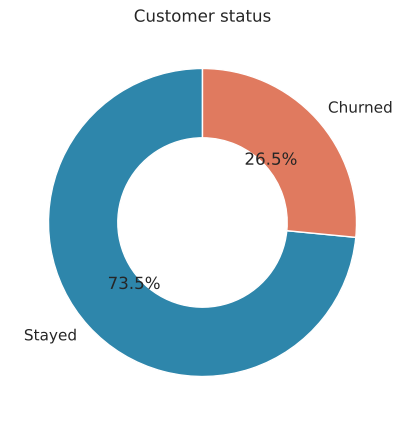

In [5]:
churned = df["ChurnFlag"].sum()
total = len(df)
baseline = churned / total * 100
lost_mrr = df.loc[df["ChurnFlag"] == 1, "MonthlyCharges"].sum()
total_mrr = df["MonthlyCharges"].sum()

print(f"Churn rate = churned / total = {churned:,} / {total:,} = {baseline:.2f}%")
print(f"Monthly revenue of churned customers: ${lost_mrr:,.0f} ({lost_mrr / total_mrr:.1%} of ${total_mrr:,.0f} monthly billing)")

plt.figure(figsize=(5, 5))
plt.pie([total - churned, churned], labels=["Stayed", "Churned"], autopct="%1.1f%%",
        colors=["#2E86AB", "#E07A5F"], startangle=90, wedgeprops={"width": 0.45})
plt.title("Customer status")
plt.show()

## 3. Tenure and contract cohorts

In [6]:
# Tenure cohorts of 12 months each
bins = [-1, 12, 24, 36, 48, 60, 72]
labels = ["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"]
df["Tenure Cohort"] = pd.cut(df["tenure"], bins=bins, labels=labels)

cohort = df.groupby("Tenure Cohort", observed=True).agg(
    Customers=("customerID", "count"),
    Churned=("ChurnFlag", "sum"),
)
cohort["Churn Rate %"] = cohort["Churned"] / cohort["Customers"] * 100
cohort["Retention %"] = 100 - cohort["Churn Rate %"]
cohort

,Customers,Churned,Churn Rate %,Retention %
Tenure Cohort,,,,
0-12,2186,1037,47.44,52.56
13-24,1024,294,28.71,71.29
25-36,832,180,21.63,78.37
37-48,762,145,19.03,80.97
49-60,832,120,14.42,85.58
61-72,1407,93,6.61,93.39


,Customers,Churned,Avg_Monthly_Charge,Churn Rate %,Retention %
Contract,,,,,
Month-to-month,3875,1655,66.40,42.71,57.29
One year,1473,166,65.05,11.27,88.73
Two year,1695,48,60.77,2.83,97.17


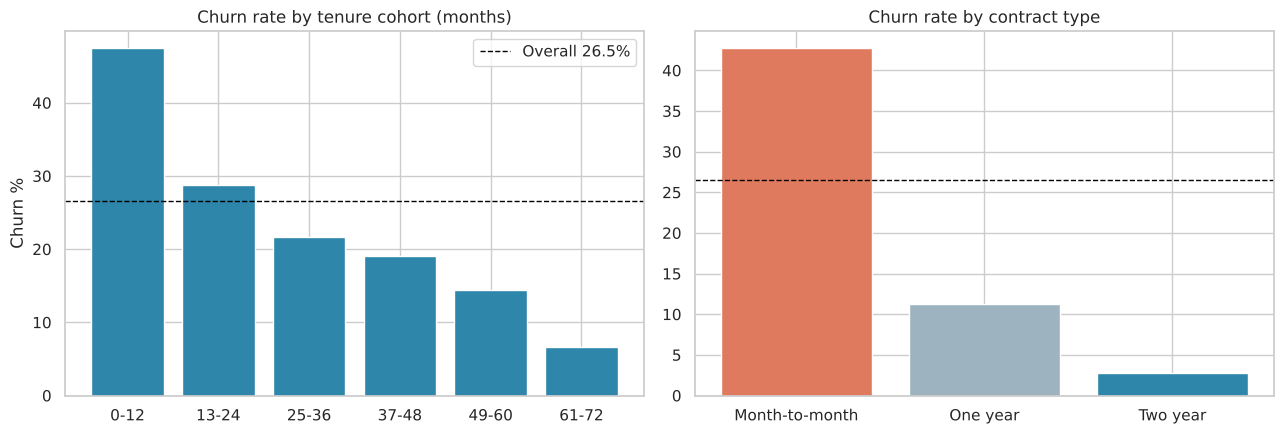

In [7]:
contract = df.groupby("Contract").agg(Customers=("customerID", "count"), Churned=("ChurnFlag", "sum"),
                                       Avg_Monthly_Charge=("MonthlyCharges", "mean"))
contract["Churn Rate %"] = contract["Churned"] / contract["Customers"] * 100
contract["Retention %"] = 100 - contract["Churn Rate %"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(cohort.index.astype(str), cohort["Churn Rate %"], color="#2E86AB")
ax[0].axhline(baseline, color="black", linestyle="--", linewidth=1, label=f"Overall {baseline:.1f}%")
ax[0].set_title("Churn rate by tenure cohort (months)")
ax[0].set_ylabel("Churn %")
ax[0].legend()

ax[1].bar(contract.index, contract["Churn Rate %"], color=["#E07A5F", "#9DB4C0", "#2E86AB"])
ax[1].axhline(baseline, color="black", linestyle="--", linewidth=1)
ax[1].set_title("Churn rate by contract type")
plt.tight_layout()
plt.savefig("images/01_churn_by_tenure_and_contract.png", dpi=110, bbox_inches="tight")
plt.show()
contract

## 4. Cohort retention matrix and retention curves

Tenure Cohort,0-12,13-24,25-36,37-48,49-60,61-72
Contract,,,,,,
Month-to-month,48.60,62.30,67.50,66.50,72.20,77.80
One year,89.50,91.90,92.00,86.90,86.30,87.90
Two year,100.00,100.00,97.90,97.80,96.00,96.90


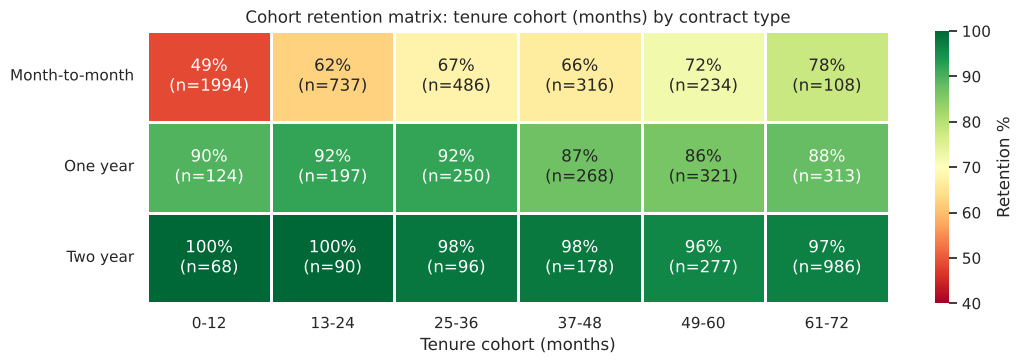

In [8]:
# Matrix: tenure cohort x contract type, showing retention % in each cell
churn_matrix = df.pivot_table(index="Contract", columns="Tenure Cohort", values="ChurnFlag", aggfunc="mean", observed=True) * 100
count_matrix = df.pivot_table(index="Contract", columns="Tenure Cohort", values="ChurnFlag", aggfunc="count", observed=True)
retention_matrix = 100 - churn_matrix

# Annotation shows retention % and the customer count behind it
annot = retention_matrix.round(0).astype("Int64").astype(str) + "%\n(n=" + count_matrix.fillna(0).astype(int).astype(str) + ")"

plt.figure(figsize=(11, 3.8))
sns.heatmap(retention_matrix, annot=annot, fmt="", cmap="RdYlGn", vmin=40, vmax=100,
            cbar_kws={"label": "Retention %"}, linewidths=1)
plt.title("Cohort retention matrix: tenure cohort (months) by contract type")
plt.xlabel("Tenure cohort (months)")
plt.ylabel("")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("images/02_cohort_retention_matrix.png", dpi=110, bbox_inches="tight")
plt.show()
retention_matrix.round(1)

**How to read it:** each cell shows the share of customers in that tenure group who are still active, and how many customers sit in the cell. Cells with small counts (for example 2-year contracts in the 0-12 band) are less reliable.

,Month 6,Month 12,Month 24,Month 36,Month 48,Month 60
Month-to-month,78.60,70.30,58.60,49.10,39.70,29.70
One year,99.70,99.10,97.80,95.90,91.70,83.20
Two year,100.00,100.00,100.00,99.90,99.60,98.60
All customers,88.50,84.30,78.90,74.90,70.90,66.40


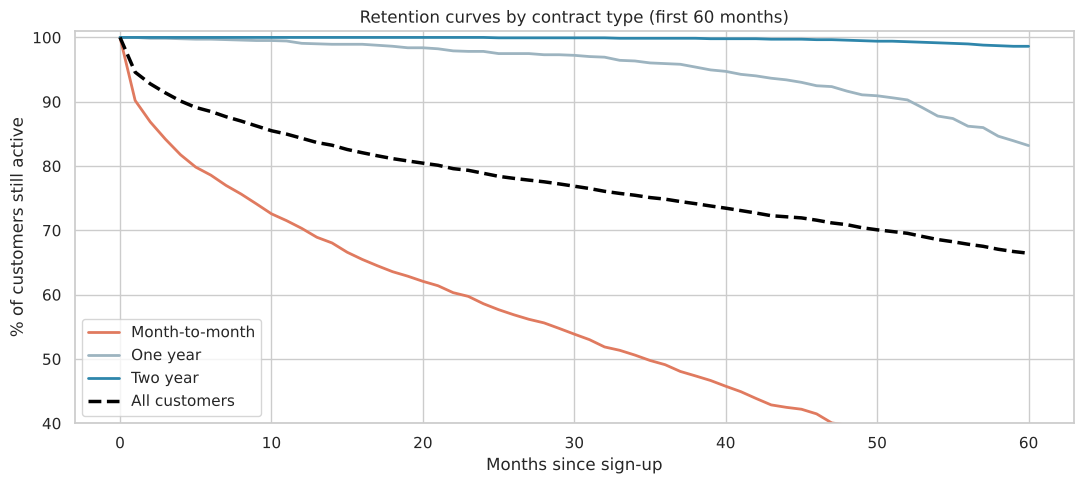

In [9]:
# Retention curve (Kaplan-Meier style).
# A customer who churned left after `tenure` months. A customer who has not churned is still active,
# so we only know they lasted at least `tenure` months. KM handles that correctly.
def retention_curve(data, max_month=60):
    n_total = np.bincount(data["tenure"], minlength=max_month + 1)
    n_churn = np.bincount(data.loc[data["ChurnFlag"] == 1, "tenure"], minlength=max_month + 1)
    at_risk = n_total[::-1].cumsum()[::-1]      # customers observed for at least t months
    surv, s = [1.0], 1.0
    for t in range(1, max_month + 1):
        s *= 1 - n_churn[t] / at_risk[t] if at_risk[t] else 1
        surv.append(s)
    return pd.Series(surv, index=range(0, max_month + 1)) * 100

curves = {c: retention_curve(df[df["Contract"] == c]) for c in ["Month-to-month", "One year", "Two year"]}
curves["All customers"] = retention_curve(df)

plt.figure(figsize=(11, 5))
colors = {"Month-to-month": "#E07A5F", "One year": "#9DB4C0", "Two year": "#2E86AB", "All customers": "black"}
for name, s in curves.items():
    plt.plot(s.index, s.values, label=name, color=colors[name], linewidth=2.5 if name == "All customers" else 2,
             linestyle="--" if name == "All customers" else "-")
plt.title("Retention curves by contract type (first 60 months)")
plt.xlabel("Months since sign-up")
plt.ylabel("% of customers still active")
plt.ylim(40, 101)
plt.legend()
plt.tight_layout()
plt.savefig("images/03_retention_curves.png", dpi=110, bbox_inches="tight")
plt.show()

milestones = [6, 12, 24, 36, 48, 60]
retention_table = pd.DataFrame({name: s.loc[milestones] for name, s in curves.items()}).T
retention_table.columns = [f"Month {m}" for m in milestones]
retention_table.round(1)

Curves stop at month 60 on purpose. Very few month-to-month customers have been around for more than 60 months (only 2 at month 72), so later points would not be reliable.

## 5. Churn drivers

                           Customers  Churn_Rate
PaymentMethod                                   
Electronic check                2365       45.30
Mailed check                    1612       19.10
Bank transfer (automatic)       1544       16.70
Credit card (automatic)         1522       15.20

             Customers  Churn_Rate
Charge Band                       
Up to $35         1735       10.90
$35-65            1409       23.10
$65-90            2160       36.30
Above $90         1739       32.80

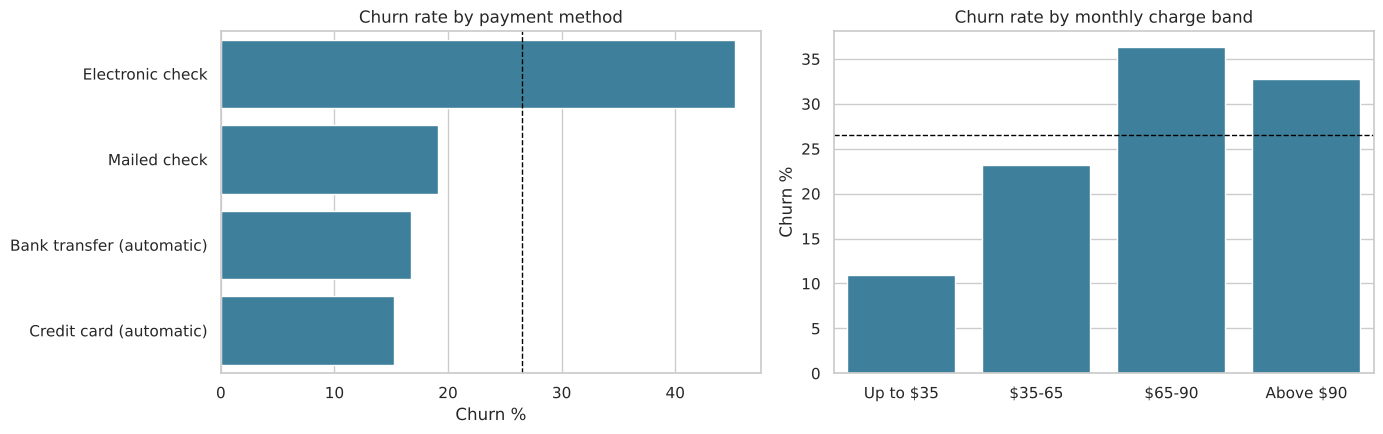

In [10]:
# Payment method
pay = df.groupby("PaymentMethod").agg(Customers=("customerID", "count"), Churn_Rate=("ChurnFlag", "mean"))
pay["Churn_Rate"] *= 100
pay = pay.sort_values("Churn_Rate", ascending=False)

# Monthly charge bands
df["Charge Band"] = pd.cut(df["MonthlyCharges"], bins=[0, 35, 65, 90, 200],
                           labels=["Up to $35", "$35-65", "$65-90", "Above $90"])
chg = df.groupby("Charge Band", observed=True).agg(Customers=("customerID", "count"), Churn_Rate=("ChurnFlag", "mean"))
chg["Churn_Rate"] *= 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=pay["Churn_Rate"], y=pay.index, color="#2E86AB", ax=ax[0])
ax[0].axvline(baseline, color="black", linestyle="--", linewidth=1)
ax[0].set_title("Churn rate by payment method")
ax[0].set_xlabel("Churn %")
ax[0].set_ylabel("")

sns.barplot(x=chg.index.astype(str), y=chg["Churn_Rate"], color="#2E86AB", ax=ax[1])
ax[1].axhline(baseline, color="black", linestyle="--", linewidth=1)
ax[1].set_title("Churn rate by monthly charge band")
ax[1].set_ylabel("Churn %")
ax[1].set_xlabel("")
plt.tight_layout()
plt.savefig("images/04_churn_by_payment_and_charges.png", dpi=110, bbox_inches="tight")
plt.show()
print(pay.round(1))
print()
print(chg.round(1))

In [11]:
# Service tier: internet type and add-on services
internet = df.groupby("InternetService").agg(Customers=("customerID", "count"), Churn_Rate=("ChurnFlag", "mean"),
                                              Avg_Monthly=("MonthlyCharges", "mean"))
internet["Churn_Rate"] *= 100
print(internet.round(1))

# Add-on services, only for customers who have internet
net = df[df["InternetService"] != "No"]
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
rows = []
for a in addons:
    r = net.groupby(a)["ChurnFlag"].mean() * 100
    rows.append({"Service": a, "Has it": r["Yes"], "Does not have it": r["No"]})
addon_df = pd.DataFrame(rows).set_index("Service")
addon_df["Gap (points)"] = addon_df["Does not have it"] - addon_df["Has it"]
addon_df.round(1)

                 Customers  Churn_Rate  Avg_Monthly
InternetService                                    
DSL                   2421       19.00        58.10
Fiber optic           3096       41.90        91.50
No                    1526        7.40        21.10

,Has it,Does not have it,Gap (points)
Service,,,
OnlineSecurity,14.60,41.80,27.20
OnlineBackup,21.50,39.90,18.40
DeviceProtection,22.50,39.10,16.60
TechSupport,15.20,41.60,26.50
StreamingTV,30.10,33.50,3.50
StreamingMovies,29.90,33.70,3.70


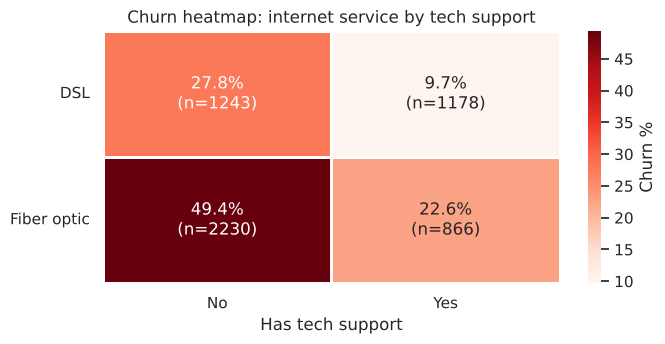

In [12]:
# Churn heatmap: internet service tier x tech support
heat = net.pivot_table(index="InternetService", columns="TechSupport", values="ChurnFlag", aggfunc="mean") * 100
heat_n = net.pivot_table(index="InternetService", columns="TechSupport", values="ChurnFlag", aggfunc="count")
annot = heat.round(1).astype(str) + "%\n(n=" + heat_n.astype(int).astype(str) + ")"

plt.figure(figsize=(7, 3.6))
sns.heatmap(heat, annot=annot, fmt="", cmap="Reds", cbar_kws={"label": "Churn %"}, linewidths=1)
plt.title("Churn heatmap: internet service by tech support")
plt.xlabel("Has tech support")
plt.ylabel("")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("images/05_churn_heatmap_service_tier.png", dpi=110, bbox_inches="tight")
plt.show()

,Cramer's V
Contract,0.41
tenure,0.35
OnlineSecurity,0.35
TechSupport,0.34
InternetService,0.32
PaymentMethod,0.30


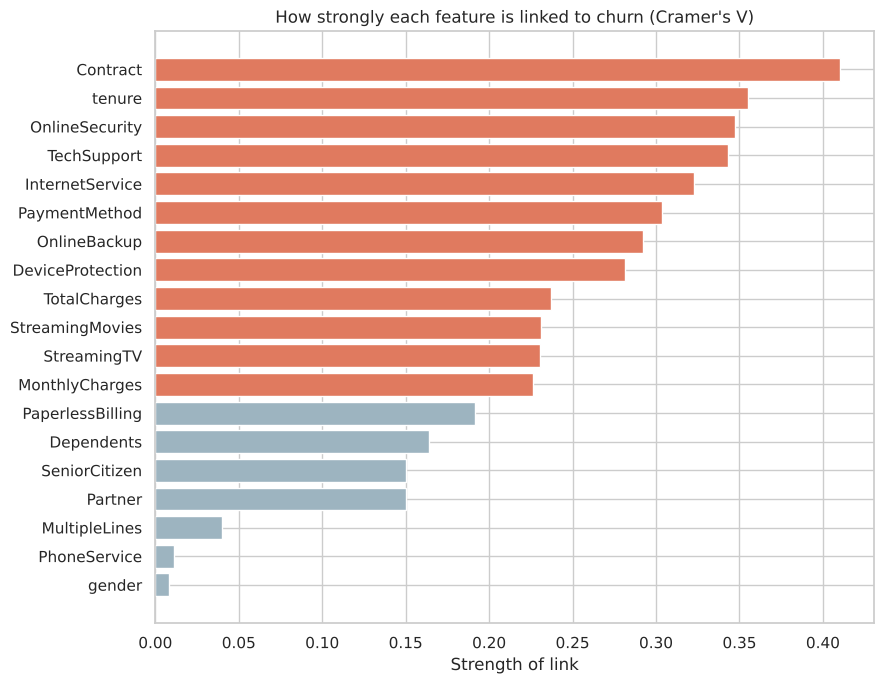

In [13]:
# Rank every feature by how strongly it is linked to churn (Cramer's V, 0 = no link, 1 = perfect link)
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

features = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
            "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod"]
scores = {f: cramers_v(df[f], df["Churn"]) for f in features}
# numeric columns grouped into quartiles so the same measure can be used
for f in ["tenure", "MonthlyCharges", "TotalCharges"]:
    scores[f] = cramers_v(pd.qcut(df[f], 4, duplicates="drop"), df["Churn"])

driver = pd.Series(scores).sort_values()
plt.figure(figsize=(9, 7))
plt.barh(driver.index, driver.values, color=["#E07A5F" if v > 0.2 else "#9DB4C0" for v in driver.values])
plt.title("How strongly each feature is linked to churn (Cramer's V)")
plt.xlabel("Strength of link")
plt.tight_layout()
plt.savefig("images/06_churn_drivers.png", dpi=110, bbox_inches="tight")
plt.show()
driver.sort_values(ascending=False).head(6).round(3).to_frame("Cramer's V")

## 6. High-risk segments

In [14]:
segments = {
    "Month-to-month contract": df["Contract"] == "Month-to-month",
    "Fiber optic, no tech support": (df["InternetService"] == "Fiber optic") & (df["TechSupport"] == "No"),
    "Month-to-month + electronic check": (df["Contract"] == "Month-to-month") & (df["PaymentMethod"] == "Electronic check"),
    "New customers (0-12 months) on month-to-month": (df["tenure"] <= 12) & (df["Contract"] == "Month-to-month"),
    "Month-to-month + Fiber optic + no tech support + no online security":
        (df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic")
        & (df["TechSupport"] == "No") & (df["OnlineSecurity"] == "No"),
}
low_risk = {
    "Two-year contract": df["Contract"] == "Two year",
    "Has tech support and online security (internet users)":
        (df["TechSupport"] == "Yes") & (df["OnlineSecurity"] == "Yes"),
}

rows = []
for name, mask in {**segments, **low_risk}.items():
    g = df[mask]
    rows.append({"Segment": name, "Customers": len(g), "% of base": len(g) / len(df) * 100,
                 "Churn Rate %": g["ChurnFlag"].mean() * 100,
                 "Lift vs average": g["ChurnFlag"].mean() / df["ChurnFlag"].mean(),
                 "Monthly revenue lost $": g.loc[g["ChurnFlag"] == 1, "MonthlyCharges"].sum()})
seg = pd.DataFrame(rows).set_index("Segment")
seg.round(1)

,Customers,% of base,Churn Rate %,Lift vs average,Monthly revenue lost $
Segment,,,,,
Month-to-month contract,3875,55.00,42.70,1.60,"120,847.10"
"Fiber optic, no tech support",2230,31.70,49.40,1.90,"94,900.80"
Month-to-month + electronic check,1850,26.30,53.70,2.00,"77,315.60"
New customers (0-12 months) on month-to-month,1994,28.30,51.40,1.90,"68,301.40"
Month-to-month + Fiber optic + no tech support + no online security,1524,21.60,60.70,2.30,"78,365.80"
Two-year contract,1695,24.10,2.80,0.10,"4,165.30"
Has tech support and online security (internet users),1099,15.60,9.00,0.30,"8,509.20"


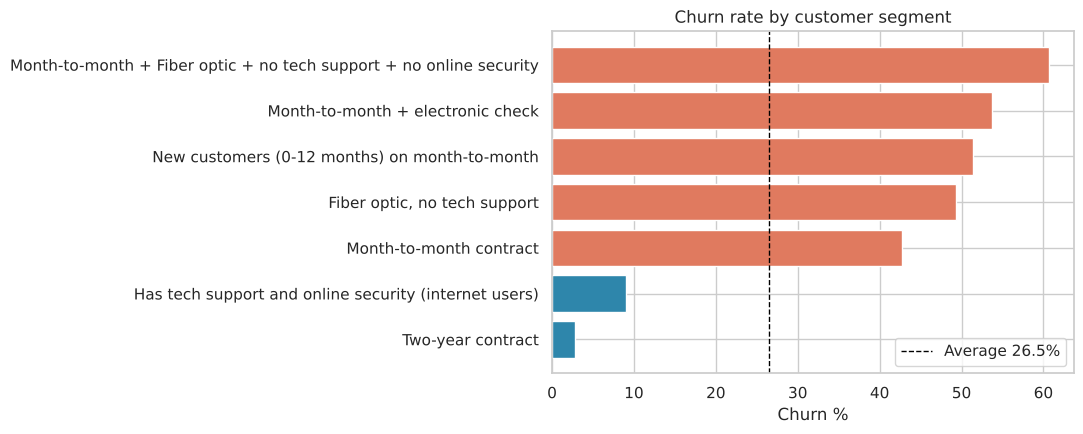

In [15]:
plt.figure(figsize=(11, 4.5))
s = seg.sort_values("Churn Rate %")
colors = ["#2E86AB" if v < baseline else "#E07A5F" for v in s["Churn Rate %"]]
plt.barh(s.index, s["Churn Rate %"], color=colors)
plt.axvline(baseline, color="black", linestyle="--", linewidth=1, label=f"Average {baseline:.1f}%")
plt.title("Churn rate by customer segment")
plt.xlabel("Churn %")
plt.legend()
plt.tight_layout()
plt.savefig("images/07_segment_churn.png", dpi=110, bbox_inches="tight")
plt.show()

In [16]:
# Numbers used in the written findings
print(f"Baseline churn: {baseline:.1f}%")
print(f"Customers who churned in first 12 months share of all churn: {df[(df['ChurnFlag']==1)&(df['tenure']<=12)].shape[0] / churned:.1%}")
print(f"Month-to-month share of customers: {(df['Contract']=='Month-to-month').mean():.1%}, share of all churners: {df.loc[df['ChurnFlag']==1,'Contract'].eq('Month-to-month').mean():.1%}")
print(f"Fiber optic: churn {internet.loc['Fiber optic','Churn_Rate']:.1f}%, DSL {internet.loc['DSL','Churn_Rate']:.1f}%, No internet {internet.loc['No','Churn_Rate']:.1f}%")
print(f"Average monthly charge, churned vs stayed: ${df.loc[df.ChurnFlag==1,'MonthlyCharges'].mean():.0f} vs ${df.loc[df.ChurnFlag==0,'MonthlyCharges'].mean():.0f}")
print(f"Average tenure, churned vs stayed: {df.loc[df.ChurnFlag==1,'tenure'].mean():.1f} vs {df.loc[df.ChurnFlag==0,'tenure'].mean():.1f} months")
print(f"Electronic check share of customers: {(df['PaymentMethod']=='Electronic check').mean():.1%}")
print(f"Senior citizens churn: {df.loc[df.SeniorCitizen=='Yes','ChurnFlag'].mean():.1%} vs others {df.loc[df.SeniorCitizen=='No','ChurnFlag'].mean():.1%}")
print(f"Gender gap: {df.groupby('gender')['ChurnFlag'].mean().round(3).to_dict()}")
print()
print(retention_table.round(1).to_string())
print()
print(addon_df.round(1).to_string())
print()
print(seg.round(1).to_string())

Baseline churn: 26.5%
Customers who churned in first 12 months share of all churn: 55.5%
Month-to-month share of customers: 55.0%, share of all churners: 88.6%
Fiber optic: churn 41.9%, DSL 19.0%, No internet 7.4%
Average monthly charge, churned vs stayed: $74 vs $61
Average tenure, churned vs stayed: 18.0 vs 37.6 months
Electronic check share of customers: 33.6%
Senior citizens churn: 41.7% vs others 23.6%
Gender gap: {'Female': 0.269, 'Male': 0.262}

                Month 6  Month 12  Month 24  Month 36  Month 48  Month 60
Month-to-month    78.60     70.30     58.60     49.10     39.70     29.70
One year          99.70     99.10     97.80     95.90     91.70     83.20
Two year         100.00    100.00    100.00     99.90     99.60     98.60
All customers     88.50     84.30     78.90     74.90     70.90     66.40

                  Has it  Does not have it  Gap (points)
Service                                                 
OnlineSecurity     14.60             41.80         27.20
O

## 7. Findings and retention recommendations

**Baseline:** 1,869 of 7,043 customers churned, a churn rate of **26.5%**. Those customers paid $139K a month, which is 30.5% of total monthly billing.

### What the data shows

**1. The first year is where customers are lost.**
The 0-12 month cohort has a 47.4% churn rate. It holds 55.5% of everyone who ever churned. By the 61-72 month cohort churn is down to 6.6%. A customer who survives year one is far more likely to stay.

**2. Contract type is the strongest churn driver.**
Month-to-month customers churn at 42.7%, one-year customers at 11.3% and two-year customers at 2.8%. Month-to-month is 55% of the base but 88.6% of all churners. On the retention curves, 70% of month-to-month customers are still active at month 12 and 30% at month 60. For one-year contracts the figures are 99% and 83%, and for two-year contracts 100% and 99%.

**3. Fiber optic customers leave much more often than DSL customers.**
Fiber churn is 41.9% against 19.0% for DSL and 7.4% for customers with no internet. Fiber is also the most expensive plan ($91.50 average bill against $58.10 for DSL). Churn is highest in the $65-90 band (36.3%), and churned customers paid more on average ($74 against $61).

**4. Support and security add-ons are linked to much lower churn.**
Customers without Online Security churn at 41.8% against 14.6% for those with it. The Tech Support gap is similar (41.6% against 15.2%). Fiber customers without tech support churn at 49.4%, and with tech support at 22.6%. Streaming add-ons show almost no gap (about 3.5 points). This is a link, not proof of cause: customers who take these add-ons may simply be more engaged.

**5. Electronic check payers are the most likely to leave.**
Electronic check churn is 45.3%, against 15.2% to 19.1% for every other method. Inside the month-to-month group the gap holds (53.7% against about 32% to 34%). Electronic check is used by 33.6% of customers. Automatic payment customers are more settled.

**6. Senior citizens churn more, gender makes no difference.**
Senior citizens churn at 41.7% against 23.6% for others. Female and male churn are almost the same (26.9% and 26.2%).

### High-risk segments

| Segment | Customers | Churn rate | vs average | Monthly revenue lost |
|---|---|---|---|---|
| Month-to-month + Fiber + no tech support + no online security | 1,524 | 60.7% | 2.3x | $78.4K |
| Month-to-month + electronic check | 1,850 | 53.7% | 2.0x | $77.3K |
| New customers (0-12 months) on month-to-month | 1,994 | 51.4% | 1.9x | $68.3K |
| Fiber optic, no tech support | 2,230 | 49.4% | 1.9x | $94.9K |
| Month-to-month (all) | 3,875 | 42.7% | 1.6x | $120.8K |

For comparison, customers with both Tech Support and Online Security churn at only 9.0%, and two-year contract customers at 2.8%.

### Strategic retention recommendations

1. **Run a first-year program.** Add a welcome call in month 1 and check-ins at months 3 and 6 for every new customer. Start with the 1,994 new month-to-month customers, who churn at 51%.
2. **Move month-to-month customers to one-year contracts.** Offer a price lock or small discount at months 3 to 6. The data shows 42.7% against 11.3% churn, though part of that gap is because loyal customers choose longer contracts, so test the offer before rolling it out.
3. **Bundle Tech Support and Online Security for new Fiber customers.** Offer them free for the first 6 months and compare churn against a control group.
4. **Push electronic check customers to auto-pay.** A small monthly credit for switching to bank transfer or card is cheap compared with the revenue at stake.
5. **Review Fiber pricing and service quality.** A 42% churn rate on the highest-priced plan points to a value or reliability problem, not only a marketing one.
6. **Build an early-warning list.** Flag customers who match two or more risk traits (month-to-month, fiber, no add-ons, electronic check, under 12 months) and contact them first.

**Size of the prize:** every 1 point drop in overall churn keeps about 70 customers, or roughly $4.5K of monthly billing (simple arithmetic on the average bill of $64.76).

### Limits of this analysis
- The data is a single snapshot with no sign-up dates, so cohorts are built from tenure (months with the company).
- Churn links shown here are correlations. Offers should be tested before a full rollout.
- Cells with few customers (for example two-year contracts in the first 12 months) should be read with care.